# D02 · Valid JSON is only the first gate
Visualize the gap between parsing, schema validity and executable meaning. Run a small AST through the repository’s real bounded interpreter and change its semantics without breaking its syntax.
**Prerequisites:** basic Python and the [learning guide](../docs/LEARNING_GUIDE.md).
**Evidence boundary:** the charts read the recorded October 26, 2026 experiments by default. Running this notebook recomputes plots and teaching calculations; it does not retrain a model or run new model inference. Illustrative examples below are labeled separately. The [notebook guide](README.md) explains setup, provenance, and how to export your own completed runs.

## Load the evidence
Run all cells in order. The loader prints the run IDs, dates, seeds and scope. A custom export does not automatically rewrite the historical interpretation in this lesson.

In [1]:
from pathlib import Path
import sys
import numpy as np
import matplotlib.pyplot as plt

# Works when Jupyter starts in the repository root or notebooks/.
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / "notebooks/lab.py").is_file() and (p / "src/ml_training").is_dir())
for folder in [ROOT / "notebooks", ROOT / "src"]:
    if str(folder) not in sys.path:
        sys.path.insert(0, str(folder))
from lab import load_demo, style, grouped_bars
style()

# None uses the compact checked-in snapshot. To inspect a new export, set an
# explicit path, e.g. ROOT / "artifacts/my-notebook-results.json". Missing files fail.
SNAPSHOT_PATH = None
d = load_demo("D02", SNAPSHOT_PATH)

D02 | recorded experiment data | recorded_results.json
Recorded local educational experiments. Inspect run dates, seeds and source manifests before comparing results. No production or physical-device validation.
Run: artifacts/schema_dsl/local-s41-20261026T175054Z-61eada | recorded: 20261026T175054Z | seed: 41


## The concept
Structured generation has several contracts. JSON parsing checks representation; schema validation checks allowed fields and types; execution compares the behavior with the intended query. These gates can fail independently. A grammar-constrained decoder can improve structure, but cannot establish intent or authorization.

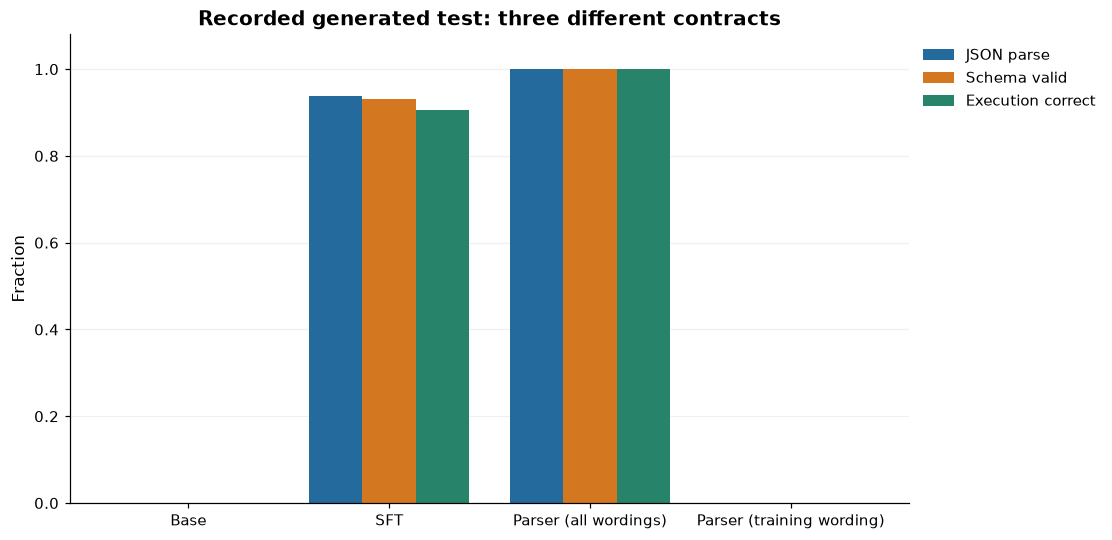

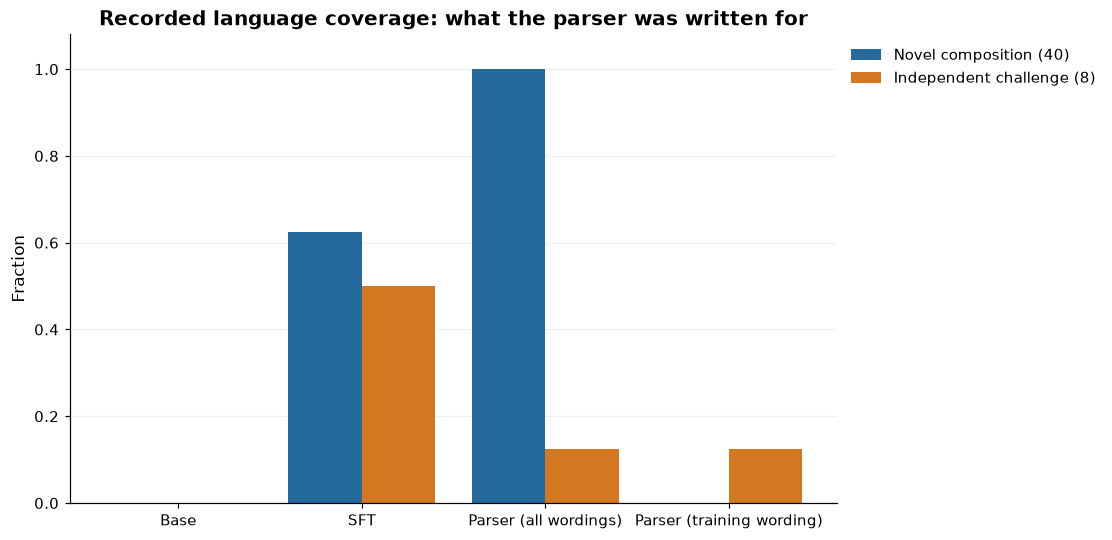

Validation selection: typed_slot as recorded; tuned when the parser knows only training wording


In [2]:
variants = ['base', 'tuned', 'typed_slot']
labels = ['Base', 'SFT', 'Parser (all wordings)']
test = [d['metrics'][v] for v in variants]
challenge = [d['challenge'][v] for v in variants]
fair = d.get('training_wording_baseline')
if fair:
    labels.append('Parser (training wording)')
    test.append(fair['metrics']['test'])
    challenge.append(fair['metrics']['challenge'])
grouped_bars(labels, {
    'JSON parse': [m['json_parse_rate'] for m in test],
    'Schema valid': [m['schema_validity'] for m in test],
    'Execution correct': [m['joint_accuracy'] for m in test],
}, title='Recorded generated test: three different contracts')
plt.show()
grouped_bars(labels, {
    'Novel composition (40)': [m['novel_composition_accuracy'] for m in test],
    'Independent challenge (8)': [m['joint_accuracy'] for m in challenge],
}, title='Recorded language coverage: what the parser was written for')
plt.show()
if fair:
    print(f"Validation selection: {fair['recorded_selection']} as recorded; "
          f"{fair['selection_with_training_wording_baseline']} when the parser knows only training wording")

### Run a real interpreter on a small teaching example
This table is **illustrative input**, not an evaluation fixture. The actual repository interpreter validates the AST and executes a bounded operation; it does not use `eval` or execute SQL. Change `candidate_operator` from `gt` to `lt`: both ASTs remain schema-valid while selecting different tickets. Change it to an unsupported operation to observe rejection.

Intended IDs: ['C'] | Candidate IDs: ['A'] | Same meaning on this fixture: False


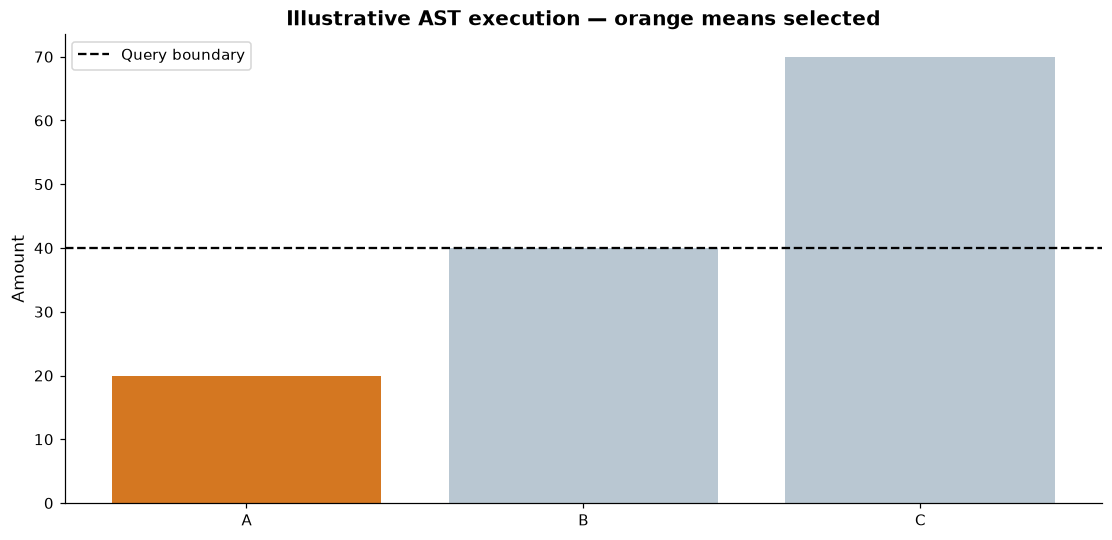

In [3]:
from ml_training.query_dsl import execute, InvalidQuery
candidate_operator = 'lt'  # Intended request: amount greater than 40.
rows = [{'id': 'A', 'amount': 20}, {'id': 'B', 'amount': 40}, {'id': 'C', 'amount': 70}]
expected = {'filter': {'field': 'amount', 'op': 'gt', 'value': 40}, 'aggregate': {'op': 'ids'}}
candidate = {'filter': {'field': 'amount', 'op': candidate_operator, 'value': 40}, 'aggregate': {'op': 'ids'}}
try:
    wanted, observed = execute(expected, rows), execute(candidate, rows)
    print('Intended IDs:', wanted, '| Candidate IDs:', observed, '| Same meaning on this fixture:', wanted == observed)
    fig, ax = plt.subplots(layout='constrained')
    ax.bar([r['id'] for r in rows], [r['amount'] for r in rows],
           color=['#d47721' if r['id'] in observed else '#b9c7d2' for r in rows])
    ax.axhline(40, color='black', ls='--', label='Query boundary')
    ax.set(title='Illustrative AST execution — orange means selected', ylabel='Amount')
    ax.legend(); plt.show()
except InvalidQuery as error:
    print('Rejected before execution:', error)

**Interpretation check:** the recorded parser was written knowing every split's wording, including the held-out test phrasing the models never saw. That is why it scored 100% on generated tests. Restricted to training wording, like the models, it parses none of the validation or test requests, and the same validation rule selects SFT instead. Hand-written rules cover exactly the wording they were written for. SFT carried over to new phrasing at 90.6% but fell to 62.5% on new field combinations, and both handle few independent challenges.

Before comparing a baseline with a trained model, check that both had the same information. A single table also cannot prove two queries equivalent: different filters can coincide on empty or uninformative data. Use multiple independently constructed fixtures.

## What you learned and when to use it
SFT can improve structured behavior. Typed input and constrained decoding are credible alternatives when you control the request wording. Keep validation and authorization outside the model. Separate format improvements from semantic correctness in every report.
**Architecture exercise:** state a quality floor, a simpler alternative, and the evidence that would make you reject this approach. Compare your answer with the [decision guide](../docs/ARCHITECTURE_DECISION_GUIDE.md#d02--tune-structured-generation).
**Train or run the actual model:** follow the [D02 tutorial](../docs/SLM_DEMOS.md#d02-strict-syntax-and-executable-semantics). Training stays in its existing locked environment; this notebook stays light enough to run without model downloads.
[All visual lessons](README.md) · [Production tradeoffs](../docs/PRODUCTION_TRADEOFFS.md)